In [ ]:
#Moran’s I 라이브러리 설치
# [셀 B1] ③④ 준비: 라이브러리 설치 + 파일 확인
!pip -q install esda libpysal
import os, warnings, numpy as np, pandas as pd, geopandas as gpd
from google.colab import files
warnings.filterwarnings("ignore")
miss = [f for f in ["dong_master.csv", "dong_boundary.gpkg"] if not os.path.exists(f)]
if miss:
    print("올릴 파일:", miss)
    for f in files.upload():
        if f.startswith("dong_master") and f != "dong_master.csv": os.rename(f, "dong_master.csv")   # "(1)" 붙은 이름 정리
dm = pd.read_csv("dong_master.csv", dtype={"adm_cd": str})
print("동 수:", len(dm), "/ 빠진 열:", [c for c in ["acc_600", "acc_1000", "island"] if c not in dm])

올릴 파일: ['dong_master.csv', 'dong_boundary.gpkg']


Saving dong_master_new.csv to dong_master_new.csv
Saving kmeans_input.csv to kmeans_input.csv
Saving dong_boundary.gpkg to dong_boundary.gpkg
동 수: 156 / 빠진 열: []


In [ ]:
# [셀 B2] ③ 취약지역 판정: 600m 하위 p% 중 1km에서도 하위 p%면 확정, 600m에서만이면 경계 (p = 15·20·25%)
def bottom(col, p):
    return dm[col].rank(method="min") <= round(len(dm) * p / 100)      # 동점은 같은 순위로 함께 포함
for p in (15, 20, 25):
    b600, b1000 = bottom("acc_600", p), bottom("acc_1000", p)
    dm[f"vuln_{p}"] = np.select([b600 & b1000, b600], ["확정", "경계"], "비취약")
    print(f"[하위 {p}%] 확정 {(dm[f'vuln_{p}'] == '확정').sum()} / 경계 {(dm[f'vuln_{p}'] == '경계').sum()}"
          f" / 1km에서만 하위 {(b1000 & ~b600).sum()}")
dm["vuln"] = dm["vuln_20"]                                               # 주 기준 20%
for v in ["확정", "경계"]: print(f"\n[20% {v}]", dm.loc[dm["vuln"] == v, "adm_nm"].tolist())

[하위 15%] 확정 22 / 경계 1 / 1km에서만 하위 1
[하위 20%] 확정 28 / 경계 3 / 1km에서만 하위 3
[하위 25%] 확정 32 / 경계 7 / 1km에서만 하위 7

[20% 확정] ['용유동', '영종동', '개항동', '만석동', '화수2동', '장수서창동', '부평3동', '산곡3동', '삼산1동', '문학동', '선원면', '불은면', '길상면', '화도면', '양도면', '내가면', '하점면', '양사면', '송해면', '교동면', '삼산면', '서도면', '북도면', '백령면', '대청면', '덕적면', '자월면', '영흥면']

[20% 경계] ['화수1·화평동', '송현1·2동', '계양1동']


In [ ]:
# [셀 B3] ④ 공간 가중치: Queen 인접, 이웃이 없는 섬은 가장 가까운 4개 동을 이웃으로
from libpysal.weights import Queen, KNN, W
bnd = gpd.read_file("dong_boundary.gpkg").to_crs(5179).astype({"adm_cd": str})
g = bnd[["adm_cd", "geometry"]].merge(dm, on="adm_cd").reset_index(drop=True)
print("경계-표 매칭:", len(g), "/", len(dm))
wq = Queen.from_dataframe(g, use_index=False, silence_warnings=True)
wk = KNN.from_dataframe(g, k=4, use_index=False)                                       # 동 중심점 기준
w = W({i: list(wq.neighbors[i]) or list(wk.neighbors[i]) for i in range(len(g))}, silence_warnings=True)
w.transform = "r"
print("이웃 없어서 가까운 4개 동으로 이은 섬:", g.loc[wq.islands, "adm_nm"].tolist())
print("평균 이웃 수:", round(w.mean_neighbors, 2), "/ 연결 덩어리 수:", w.n_components)

경계-표 매칭: 156 / 156
이웃 없어서 가까운 4개 동으로 이은 섬: ['교동면', '삼산면', '서도면', '북도면', '연평면', '백령면', '대청면', '덕적면', '자월면', '영흥면']
평균 이웃 수: 4.94 / 연결 덩어리 수: 2


In [ ]:
# [셀 B4] ④ 전역 Moran's I(999회 순열) + LISA(0.05) → 취약지역을 밀집형·고립형·산발형으로
from esda.moran import Moran, Moran_Local
np.random.seed(42)
for c in ["acc_600", "acc_1000"]:
    mi = Moran(g[c].to_numpy(), w, permutations=999)
    print(f"[{c}] Moran's I = {mi.I:.3f} (무작위면 {mi.EI:.3f}) / p = {mi.p_sim:.3f}")
lisa = Moran_Local(g["acc_600"].to_numpy(), w, permutations=999, seed=42)
g["lisa"] = np.where(lisa.p_sim < 0.05, np.array(["", "HH", "LH", "LL", "HL"])[lisa.q], "ns")
g["lisa_p"] = lisa.p_sim.round(3)
g["pattern"] = np.where(g["vuln"] == "비취약", "", g["lisa"].map({"LL": "밀집형", "LH": "고립형"}).fillna("산발형"))
print("\nLISA 전체 동:", g["lisa"].value_counts().to_dict())
s = g[g["vuln"] != "비취약"]; print(pd.crosstab(s["vuln"], s["pattern"]).to_string())
for k in ["밀집형", "고립형", "산발형"]: print(f"\n[{k}]", g.loc[g["pattern"] == k, "adm_nm"].tolist())
dm = dm.drop(columns=["lisa", "lisa_p", "pattern"], errors="ignore").merge(g[["adm_cd", "lisa", "lisa_p", "pattern"]], on="adm_cd", how="left")

[acc_600] Moran's I = 0.283 (무작위면 -0.006) / p = 0.001
[acc_1000] Moran's I = 0.359 (무작위면 -0.006) / p = 0.001

LISA 전체 동: {'ns': 119, 'LL': 14, 'HH': 14, 'LH': 7, 'HL': 2}
pattern  고립형  밀집형  산발형
vuln                  
경계         0    0    3
확정         1   13   14

[밀집형] ['불은면', '길상면', '화도면', '양도면', '내가면', '하점면', '양사면', '교동면', '삼산면', '서도면', '북도면', '덕적면', '자월면']

[고립형] ['삼산1동']

[산발형] ['용유동', '영종동', '개항동', '만석동', '화수1·화평동', '화수2동', '송현1·2동', '장수서창동', '부평3동', '산곡3동', '계양1동', '문학동', '선원면', '송해면', '백령면', '대청면', '영흥면']


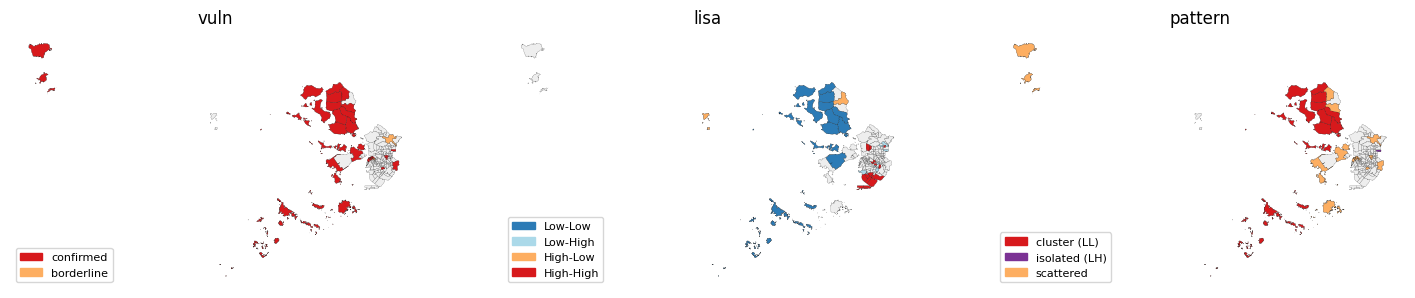

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# [셀 B5] 지도 3장(판정 / LISA / 취약지역 패턴) + 저장·다운로드
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
MAPS = [("vuln", {"확정": ("confirmed", "#d7191c"), "경계": ("borderline", "#fdae61")}),
        ("lisa", {"LL": ("Low-Low", "#2c7bb6"), "LH": ("Low-High", "#abd9e9"), "HL": ("High-Low", "#fdae61"), "HH": ("High-High", "#d7191c")}),
        ("pattern", {"밀집형": ("cluster (LL)", "#d7191c"), "고립형": ("isolated (LH)", "#7b3294"), "산발형": ("scattered", "#fdae61")})]
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (col, pal) in zip(ax, MAPS):
    g.plot(ax=a, color="#eeeeee", edgecolor="k", linewidth=0.1)
    for k, (lab, colr) in pal.items():
        if (g[col] == k).any(): g[g[col] == k].plot(ax=a, color=colr, edgecolor="k", linewidth=0.1)
    a.legend(handles=[Patch(color=c, label=l) for l, c in pal.values()], loc="lower left", fontsize=8)
    a.set_title(col); a.axis("off")
plt.show()
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")
files.download("dong_master.csv")

In [ ]:
#정확히 어느 동인지 확인
for k in ["HH", "HL"]: print(k, dm.loc[dm["lisa"] == k, "adm_nm"].tolist())

HH ['동춘1동', '동춘2동', '송도1동', '송도3동', '송도2동', '송도4동', '구월1동', '논현고잔동', '계산4동', '청라1동', '청라2동', '도화1동', '주안4동', '주안5동']
HL ['강화읍', '연평면']


In [ ]:
# [셀 C1] ⑤ K 고르기: K = 3~6에서 엘보우(SSE)와 실루엣 계수
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X = pd.read_csv("kmeans_input.csv", dtype={"adm_cd": str})
VARS = ["acc_600", "d_bus_w", "eld_single_ratio"]; ZC = [c + "_z" for c in VARS]
Z, SEED = X[ZC].to_numpy(), 42
print("K-means 대상 동:", len(X))
for k in range(3, 7):
    km = KMeans(k, n_init=50, random_state=SEED).fit(Z)
    print(f"K={k}: SSE {km.inertia_:6.1f} / 실루엣 {silhouette_score(Z, km.labels_):.3f} / 군집 크기 {sorted(np.bincount(km.labels_).tolist(), reverse=True)}")

K-means 대상 동: 149
K=3: SSE  220.0 / 실루엣 0.306 / 군집 크기 [84, 52, 13]
K=4: SSE  175.5 / 실루엣 0.288 / 군집 크기 [59, 48, 29, 13]
K=5: SSE  147.0 / 실루엣 0.296 / 군집 크기 [43, 34, 33, 26, 13]
K=6: SSE  124.9 / 실루엣 0.312 / 군집 크기 [41, 36, 33, 18, 13, 8]


In [ ]:
# [셀 C1-2] K = 3~6 군집 안정성 비교: 80% 재표본 100회, 군집별 평균 Jaccard
def stability(k, B=100):
    base = KMeans(k, n_init=50, random_state=SEED).fit(Z).labels_
    rng, n, jac = np.random.default_rng(SEED), len(Z), {c: [] for c in range(k)}
    for b in range(B):
        idx = rng.choice(n, int(n * 0.8), replace=False)
        lb = KMeans(k, n_init=50, random_state=SEED + b).fit(Z[idx]).labels_
        for c in range(k):
            A = set(idx[base[idx] == c])
            if A: jac[c].append(max(len(A & set(idx[lb == d])) / len(A | set(idx[lb == d])) for d in range(k)))
    return [float(round(np.mean(jac[c]), 2)) for c in range(k)], np.bincount(base).tolist()
for k in range(3, 7):
    j, size = stability(k)
    print(f"K={k}: 군집별 Jaccard {j} / 군집 크기 {size} / 최솟값 {min(j)}")

K=3: 군집별 Jaccard [0.89, 0.9, 0.91] / 군집 크기 [13, 52, 84] / 최솟값 0.89
K=4: 군집별 Jaccard [0.84, 0.95, 0.81, 0.87] / 군집 크기 [59, 13, 29, 48] / 최솟값 0.81
K=5: 군집별 Jaccard [0.82, 0.78, 0.81, 0.97, 0.66] / 군집 크기 [26, 34, 43, 13, 33] / 최솟값 0.66
K=6: 군집별 Jaccard [0.72, 0.79, 0.86, 0.85, 1.0, 0.76] / 군집 크기 [36, 33, 41, 18, 13, 8] / 최솟값 0.72


In [ ]:
# K = 3일 때
# [셀 C2] 고른 K로 군집 → 군집별 평균을 보고 이름 붙이기
K = 3                                                     # ← C1 결과 보고 바꿔
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
X["cluster"] = km.labels_ + 1
prof = X.groupby("cluster").agg(동수=("adm_cd", "size"), **{v: (v, "mean") for v in VARS}, **{v: (v, "mean") for v in ZC}).round(2)
print(prof.to_string())
print("전체 평균:", X[VARS].mean().round(2).to_dict())
for c in range(1, K + 1): print(f"\n[군집 {c}]", X.loc[X["cluster"] == c, "adm_nm"].tolist())

         동수  acc_600  d_bus_w  eld_single_ratio  acc_600_z  d_bus_w_z  eld_single_ratio_z
cluster                                                                                  
1        13     0.06   255.37             31.67      -1.76       2.45                0.32
2        52     3.30   118.07             22.58       0.89      -0.22               -0.82
3        84     1.31   116.66             32.80      -0.28      -0.25                0.46
전체 평균: {'acc_600': 1.9, 'd_bus_w': 129.25, 'eld_single_ratio': 29.14}

[군집 1] ['용유동', '선원면', '불은면', '길상면', '화도면', '양도면', '내가면', '하점면', '양사면', '송해면', '교동면', '삼산면', '영흥면']

[군집 2] ['영종1동', '영종2동', '송림1동', '송림4동', '송림6동', '동춘1동', '동춘2동', '동춘3동', '옥련2동', '송도1동', '송도3동', '송도2동', '송도4동', '송도5동', '구월1동', '구월2동', '구월3동', '간석2동', '논현2동', '논현고잔동', '부평1동', '부평6동', '산곡1동', '산곡2동', '산곡4동', '청천2동', '부개3동', '일신동', '삼산2동', '계산3동', '작전1동', '작전서운동', '계산4동', '연희동', '석남2동', '가좌2동', '가좌3동', '가좌4동', '신현원창동', '청라1동', '청라2동', '청라3동', '오류왕길동', '당하동', '마전동', '원당동', '아라동

In [ ]:
# K = 4일 때 (4로 결정)
# [셀 C2] 고른 K로 군집 → 군집별 평균을 보고 이름 붙이기
K = 4                                                     # ← C1 결과 보고 바꿔
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
X["cluster"] = km.labels_ + 1
prof = X.groupby("cluster").agg(동수=("adm_cd", "size"), **{v: (v, "mean") for v in VARS}, **{v: (v, "mean") for v in ZC}).round(2)
print(prof.to_string())
print("전체 평균:", X[VARS].mean().round(2).to_dict())
for c in range(1, K + 1): print(f"\n[군집 {c}]", X.loc[X["cluster"] == c, "adm_nm"].tolist())

         동수  acc_600  d_bus_w  eld_single_ratio  acc_600_z  d_bus_w_z  eld_single_ratio_z
cluster                                                                                  
1        59     1.39   110.08             26.07      -0.20      -0.43               -0.38
2        13     0.06   255.37             31.67      -1.76       2.45                0.32
3        29     4.30   118.94             21.09       1.34      -0.18               -1.01
4        48     1.57   124.90             37.08      -0.08      -0.02                0.99
전체 평균: {'acc_600': 1.9, 'd_bus_w': 129.25, 'eld_single_ratio': 29.14}

[군집 1] ['신흥동', '운서동', '영종동', '송현1·2동', '송림3·5동', '송림4동', '송림6동', '옥련1동', '연수1동', '옥련2동', '송도5동', '구월1동', '간석1동', '간석2동', '간석4동', '만수2동', '만수3동', '만수4동', '만수6동', '남촌도림동', '논현1동', '논현고잔동', '장수서창동', '부평5동', '산곡1동', '산곡2동', '산곡3동', '산곡4동', '청천1동', '청천2동', '갈산1동', '갈산2동', '부개2동', '부개3동', '일신동', '십정1동', '삼산2동', '효성1동', '효성2동', '작전2동', '계양1동', '계양3동', '검암경서동', '가정2동', '가정3동', '석남2동', '가좌4동', '

cluster  cluster_nm  
1        평균형             59
2        의료·교통 동시 취약형    13
3        의료 양호형          29
4        고령 1인가구 밀집형     48
도서형      도서형              7


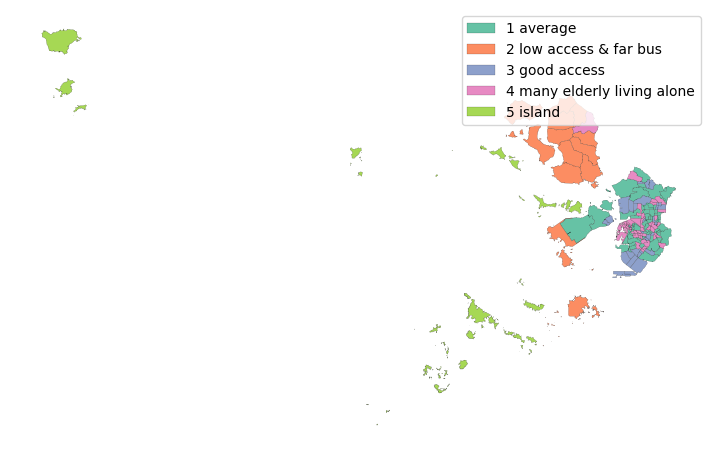

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#C3은 이전에 자카드 유사도로 한 단계임
# [셀 C4] 섬 7개는 도서형으로 붙이고 군집 이름 달기 + 저장 + 지도
NAMES = {1: "평균형", 2: "의료·교통 동시 취약형", 3: "의료 양호형", 4: "고령 1인가구 밀집형"}      # ← C2 평균표 보고 붙인 이름
EN = {1: "1 average", 2: "2 low access & far bus", 3: "3 good access", 4: "4 many elderly living alone"}
dm = dm.drop(columns=["cluster", "cluster_nm"], errors="ignore").merge(X[["adm_cd", "cluster"]], on="adm_cd", how="left")
dm["cluster_nm"] = dm["cluster"].map(NAMES).where(dm["island"] == 0, "도서형")
dm["cluster"] = dm["cluster"].astype("Int64").astype(str).where(dm["island"] == 0, "도서형")
print(dm.groupby(["cluster", "cluster_nm"]).size().to_string())
m = bnd.merge(dm[["adm_cd", "cluster"]], on="adm_cd")
m["cl"] = m["cluster"].map({str(k): v for k, v in EN.items()} | {"도서형": "5 island"})
m.plot("cl", categorical=True, legend=True, cmap="Set2", edgecolor="k", linewidth=0.1, figsize=(9, 9)).axis("off")
plt.show()
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")
files.download("dong_master.csv"); files.download("kmeans_input.csv")